
# Klasifikasi Gambar Produk Retail Menggunakan Convolutional Neural Network (CNN)

## Abstrak
Penelitian ini bertujuan membangun model klasifikasi gambar produk retail menggunakan metode Convolutional Neural Network (CNN). Dataset terdiri atas gambar produk beserta informasi nama, deskripsi, dan kategori produk. Kolom kategori digunakan sebagai label untuk melatih model berdasarkan karakteristik visual gambar.

Model dievaluasi menggunakan accuracy, precision, recall, F1-score, dan confusion matrix. Data training dibagi menjadi data pelatihan dan validasi untuk mengukur kemampuan generalisasi model.

## Tujuan Penelitian
1. Melakukan eksplorasi dan persiapan dataset gambar produk retail.
2. Mengembangkan model CNN untuk klasifikasi kategori produk.
3. Mengevaluasi kinerja model menggunakan metrik klasifikasi.
4. Menghasilkan prediksi kategori pada gambar produk yang tersedia.

## Metodologi
Tahapan penelitian meliputi:
1. Import library.
2. Eksplorasi dataset.
3. Pemeriksaan dan pencocokan gambar dengan label.
4. Pembagian data training dan validasi.
5. Pembangunan arsitektur CNN.
6. Pelatihan model.
7. Evaluasi model.
8. Prediksi gambar produk.


In [1]:

# ============================================================
# 1. IMPORT LIBRARY
# ============================================================

import os
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")

# Mengatur seed agar hasil lebih konsisten
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Python berjalan dengan TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("GPU terdeteksi:", tf.config.list_physical_devices("GPU"))


Python berjalan dengan TensorFlow: 2.22.0-rc0
NumPy: 2.5.4
Pandas: 3.0.6
GPU terdeteksi: []



## Eksplorasi Dataset

Dataset terdiri atas file CSV dan gambar produk. Kolom `ImgId` digunakan untuk menghubungkan data metadata dengan file gambar, sedangkan kolom `categories` menjadi label target klasifikasi.

Pemeriksaan awal dilakukan untuk mengetahui jumlah data, nama kolom, nilai kosong, distribusi kategori, dan kecocokan file gambar.


In [2]:

# ============================================================
# 2. MEMBACA DATASET
# ============================================================

# Folder notebook diasumsikan berada di direktori utama project
BASE_DIR = Path.cwd()

TRAIN_CSV = BASE_DIR / "raw" / "train.csv"
TEST_CSV = BASE_DIR / "raw" / "test.csv"

# Lokasi gambar sesuai struktur folder dataset
TRAIN_IMAGE_DIR = BASE_DIR / "raw" / "train" / "train"
TEST_IMAGE_DIR = BASE_DIR / "raw" / "test" / "test"

# Memastikan file yang diperlukan tersedia
for path in [TRAIN_CSV, TEST_CSV, TRAIN_IMAGE_DIR]:
    if not path.exists():
        raise FileNotFoundError(
            f"Lokasi tidak ditemukan: {path}\n"
            "Periksa kembali struktur folder project."
        )

train_df = pd.read_csv(TRAIN_CSV)
test_df = pd.read_csv(TEST_CSV)

print("Lokasi project:", BASE_DIR)
print("Ukuran data training:", train_df.shape)
print("Ukuran data testing:", test_df.shape)

print("\nKolom training:")
print(train_df.columns.tolist())

print("\nLima baris pertama:")
display(train_df.head())


Lokasi project: /Users/nikentriwardani/Desktop/ADVANCE/Tugas UTS_retail-cnn-classofocation
Ukuran data training: (46229, 4)
Ukuran data testing: (10596, 3)

Kolom training:
['ImgId', 'title', 'description', 'categories']

Lima baris pertama:


,ImgId,title,description,categories
0,B000HYL1V6,TUNGSTEN SOLDER PICK WITH HANDLE,Solder Pick for picking up molten solder when ...,"Arts, Crafts & Sewing"
1,B00006HXWY,Write Right 98167 Screen Protector for Sony T615C,We all screen. And we all need to protect thos...,Cell Phones & Accessories
2,B000GAWSBS,Casio Mens DBC310-1 Databank 300 Digital Watch...,"Bringing you precision at a glance, the Casio ...","Clothing, Shoes & Jewelry"
3,B000040JOL,Factory-Reconditioned DEWALT DW260KR Heavy-Dut...,Factory-Reconditioned DEWALT DW260KR Heavy-Dut...,Tools & Home Improvement
4,B00006IB78,Energizer 2 in 1 Light,This twoway light features a bright flashlight...,Health & Personal Care


Jumlah baris training: 46229
Jumlah kategori unik: 21

Distribusi 15 kategori terbanyak:


categories
Arts, Crafts & Sewing        2225
Beauty                       2202
Sports & Outdoors            2201
Grocery & Gourmet Food       2201
Cell Phones & Accessories    2200
Clothing, Shoes & Jewelry    2200
Tools & Home Improvement     2200
Health & Personal Care       2200
Baby Products                2200
Baby                         2200
Patio, Lawn & Garden         2200
Electronics                  2200
All Electronics              2200
Automotive                   2200
Toys & Games                 2200
Name: count, dtype: int64

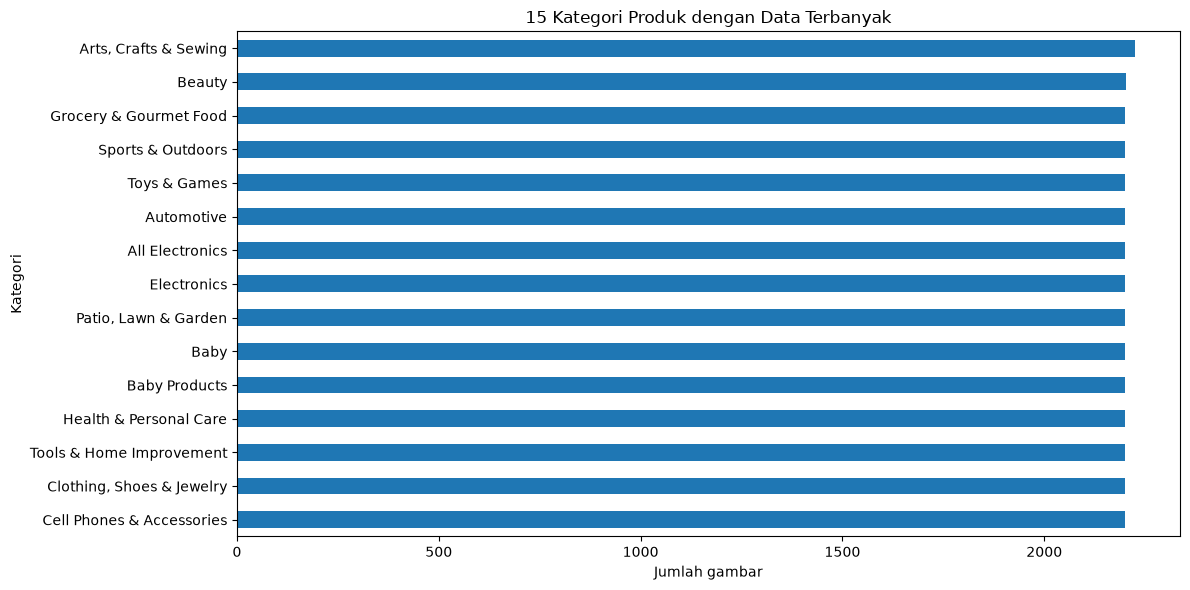

In [3]:

# ============================================================
# 3. EKSPLORASI KATEGORI
# ============================================================

# Memastikan kolom penting tersedia
required_columns = {"ImgId", "categories"}

if not required_columns.issubset(train_df.columns):
    raise ValueError(
        f"Kolom wajib tidak ditemukan. "
        f"Kolom yang diperlukan: {required_columns}"
    )

# Menghapus baris tanpa identitas gambar atau label
train_df = train_df.dropna(
    subset=["ImgId", "categories"]
).copy()

# Membersihkan spasi pada label
train_df["ImgId"] = train_df["ImgId"].astype(str).str.strip()
train_df["categories"] = train_df["categories"].astype(str).str.strip()

# Menghapus label kosong
train_df = train_df[
    (train_df["ImgId"] != "") &
    (train_df["categories"] != "")
].copy()

print("Jumlah baris training:", len(train_df))
print("Jumlah kategori unik:", train_df["categories"].nunique())

print("\nDistribusi 15 kategori terbanyak:")
display(train_df["categories"].value_counts().head(15))

# Visualisasi distribusi kategori terbanyak
top_categories = train_df["categories"].value_counts().head(15)

plt.figure(figsize=(12, 6))
top_categories.sort_values().plot(kind="barh")
plt.title("15 Kategori Produk dengan Data Terbanyak")
plt.xlabel("Jumlah gambar")
plt.ylabel("Kategori")
plt.tight_layout()
plt.show()


In [4]:

# ============================================================
# 4. VALIDASI FILE GAMBAR
# ============================================================

# Dataset menggunakan ImgId sebagai nama file gambar.
# Ekstensi .jpg ditambahkan jika belum tersedia.

def cari_gambar(img_id, folder):
    nama = str(img_id).strip()

    # Jika ImgId sudah memiliki ekstensi, gunakan nama tersebut
    kandidat = [nama] if Path(nama).suffix else [
        nama + ".jpg",
        nama + ".jpeg",
        nama + ".png"
    ]

    for file_name in kandidat:
        path = folder / file_name
        if path.is_file():
            return str(path)

    return None


train_df["image_path"] = train_df["ImgId"].apply(
    lambda x: cari_gambar(x, TRAIN_IMAGE_DIR)
)

jumlah_awal = len(train_df)

# Hanya menggunakan baris yang gambar dan labelnya tersedia
train_df = train_df.dropna(subset=["image_path"]).copy()

print("Jumlah baris sebelum validasi gambar:", jumlah_awal)
print("Jumlah gambar yang cocok:", len(train_df))
print("Jumlah gambar yang tidak ditemukan:", jumlah_awal - len(train_df))

if train_df.empty:
    raise ValueError(
        "Tidak ada gambar yang cocok. "
        "Periksa kembali ImgId dan lokasi folder gambar."
    )

# Menghindari duplikasi identitas gambar
train_df = train_df.drop_duplicates(subset=["image_path"]).copy()

print("Jumlah gambar unik yang digunakan:", len(train_df))


Jumlah baris sebelum validasi gambar: 46229
Jumlah gambar yang cocok: 42000
Jumlah gambar yang tidak ditemukan: 4229
Jumlah gambar unik yang digunakan: 42000


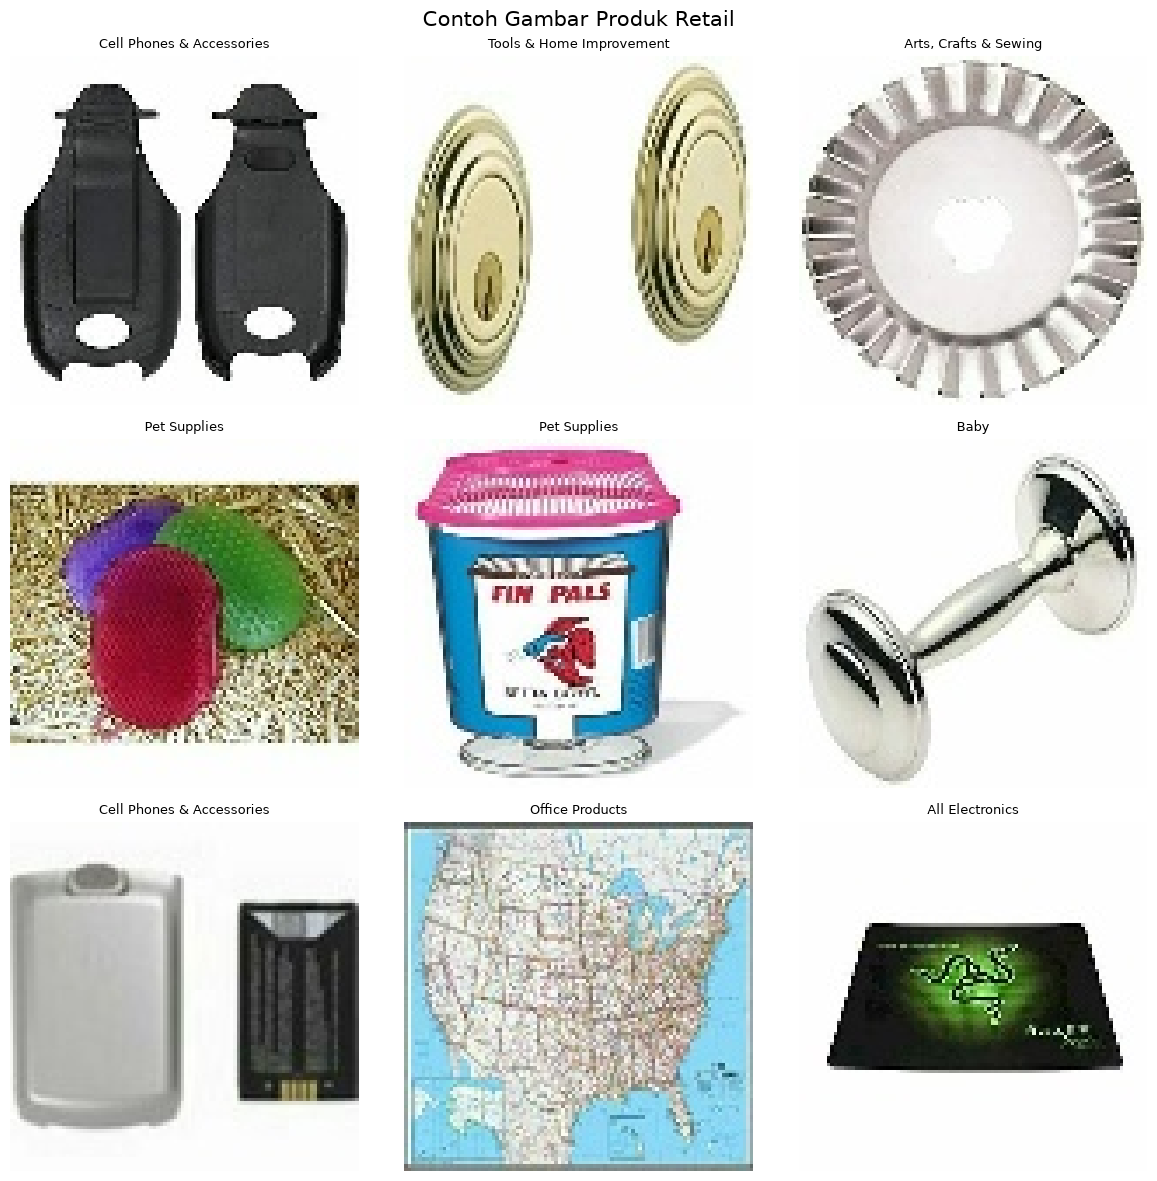

In [5]:

# ============================================================
# 5. VISUALISASI CONTOH GAMBAR
# ============================================================

jumlah_contoh = min(9, len(train_df))
contoh = train_df.sample(n=jumlah_contoh, random_state=SEED)

fig, axes = plt.subplots(3, 3, figsize=(12, 12))
axes = axes.flatten()

for ax in axes:
    ax.axis("off")

for ax, (_, row) in zip(axes, contoh.iterrows()):
    try:
        with Image.open(row["image_path"]) as img:
            ax.imshow(img.convert("RGB"))

        ax.set_title(str(row["categories"])[:60], fontsize=9)
        ax.axis("off")
    except Exception as error:
        ax.set_title("Gambar tidak dapat dibuka")
        print("Gagal membaca:", row["image_path"], error)

plt.suptitle("Contoh Gambar Produk Retail", fontsize=15)
plt.tight_layout()
plt.show()



## Persiapan Data dan Pembagian Dataset

Gambar diubah menjadi ukuran yang seragam agar dapat diproses oleh CNN. Label kategori dikonversi menjadi bilangan integer menggunakan Label Encoding.

Data berlabel kemudian dibagi menjadi data training dan validasi dengan proporsi 80:20. Data validasi digunakan untuk mengamati kemampuan model terhadap data yang tidak digunakan langsung dalam pembaruan bobot.


In [6]:

# ============================================================
# 6. ENCODING LABEL DAN PEMBAGIAN DATA
# ============================================================

# Menghapus kategori yang hanya memiliki satu gambar karena
# pembagian stratified membutuhkan setidaknya dua sampel per kelas.
jumlah_per_kategori = train_df["categories"].value_counts()
kategori_valid = jumlah_per_kategori[jumlah_per_kategori >= 2].index

data_model = train_df[
    train_df["categories"].isin(kategori_valid)
].copy()

print("Jumlah gambar setelah pemeriksaan kelas:", len(data_model))
print("Jumlah kategori yang digunakan:", data_model["categories"].nunique())

if data_model["categories"].nunique() < 2:
    raise ValueError(
        "Diperlukan setidaknya dua kategori dengan minimal dua gambar per kategori."
    )

label_encoder = LabelEncoder()
data_model["label"] = label_encoder.fit_transform(
    data_model["categories"]
)

X = data_model["image_path"].values
y = data_model["label"].values

# Pembagian 80% training dan 20% validasi
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

NUM_CLASSES = len(label_encoder.classes_)

print("Jumlah data training:", len(X_train))
print("Jumlah data validasi:", len(X_val))
print("Jumlah kelas:", NUM_CLASSES)

print("\nDaftar kategori:")
for i, kategori in enumerate(label_encoder.classes_):
    print(i, ":", kategori)


Jumlah gambar setelah pemeriksaan kelas: 42000
Jumlah kategori yang digunakan: 21
Jumlah data training: 33600
Jumlah data validasi: 8400
Jumlah kelas: 21

Daftar kategori:
0 : All Beauty
1 : All Electronics
2 : Appliances
3 : Arts, Crafts & Sewing
4 : Automotive
5 : Baby
6 : Baby Products
7 : Beauty
8 : Cell Phones & Accessories
9 : Clothing, Shoes & Jewelry
10 : Electronics
11 : Grocery & Gourmet Food
12 : Health & Personal Care
13 : Industrial & Scientific
14 : Musical Instruments
15 : Office Products
16 : Patio, Lawn & Garden
17 : Pet Supplies
18 : Sports & Outdoors
19 : Tools & Home Improvement
20 : Toys & Games


In [7]:

# ============================================================
# 7. PREPROCESSING GAMBAR
# ============================================================

# Ukuran gambar diperkecil agar pelatihan lebih ringan
IMG_HEIGHT = 96
IMG_WIDTH = 96
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE


def baca_dan_preprocess_gambar(image_path, label):
    # Membaca file gambar
    image_bytes = tf.io.read_file(image_path)

    # Dataset ini menggunakan gambar JPEG
    image = tf.io.decode_jpeg(image_bytes, channels=3)

    # Menyeragamkan ukuran gambar
    image = tf.image.resize(image, [IMG_HEIGHT, IMG_WIDTH])

    # Normalisasi nilai piksel dari 0-255 menjadi 0-1
    image = tf.cast(image, tf.float32) / 255.0

    label = tf.cast(label, tf.int32)

    return image, label


def buat_dataset(paths, labels, training=False):
    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        dataset = dataset.shuffle(
            buffer_size=min(len(paths), 5000),
            seed=SEED
        )

    dataset = dataset.map(
        baca_dan_preprocess_gambar,
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


train_dataset = buat_dataset(X_train, y_train, training=True)
val_dataset = buat_dataset(X_val, y_val, training=False)

print("Pipeline dataset berhasil dibuat.")


Pipeline dataset berhasil dibuat.



## Pembangunan Model CNN

Convolutional Neural Network (CNN) dipilih karena mampu mempelajari fitur visual dari gambar, seperti tepi, tekstur, pola, dan bentuk.

Arsitektur model terdiri atas:
1. Lapisan Conv2D untuk mengekstraksi fitur gambar.
2. MaxPooling2D untuk mengurangi dimensi fitur.
3. Dropout untuk membantu mengurangi overfitting.
4. GlobalAveragePooling2D untuk merangkum fitur.
5. Dense dan Softmax untuk menghasilkan prediksi kategori.

Model dilatih menggunakan optimizer Adam dan fungsi loss sparse categorical cross-entropy.


In [8]:

# ============================================================
# 8. MEMBANGUN ARSITEKTUR CNN
# ============================================================

model = tf.keras.Sequential([
    tf.keras.layers.Input(
        shape=(IMG_HEIGHT, IMG_WIDTH, 3)
    ),

    # Blok konvolusi pertama
    tf.keras.layers.Conv2D(
        32, (3, 3), activation="relu", padding="same"
    ),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Blok konvolusi kedua
    tf.keras.layers.Conv2D(
        64, (3, 3), activation="relu", padding="same"
    ),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Blok konvolusi ketiga
    tf.keras.layers.Conv2D(
        128, (3, 3), activation="relu", padding="same"
    ),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Klasifikasi fitur
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.30),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.20),
    tf.keras.layers.Dense(NUM_CLASSES, activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 96, 96, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 48, 48, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 24, 24, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 21)             │         2,709 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 112,469 (439.33 KB)

 Trainable params: 112,469 (439.33 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:

# ============================================================
# 9. PELATIHAN MODEL CNN
# ============================================================

# Menghentikan pelatihan jika validasi tidak membaik
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

# Menyimpan model terbaik berdasarkan validation loss
model_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(BASE_DIR / "model_cnn_terbaik.keras"),
    monitor="val_loss",
    save_best_only=True
)

EPOCHS = 5

history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS,
    callbacks=[early_stopping, model_checkpoint],
    verbose=1
)


Epoch 1/5
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 96s 91ms/step - accuracy: 0.0967 - loss: 2.9409 - val_accuracy: 0.1258 - val_loss: 2.8547
Epoch 2/5
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 95s 91ms/step - accuracy: 0.1333 - loss: 2.8405 - val_accuracy: 0.1410 - val_loss: 2.8112
Epoch 3/5
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 95s 90ms/step - accuracy: 0.1580 - loss: 2.7756 - val_accuracy: 0.1713 - val_loss: 2.7312
Epoch 4/5
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 94s 90ms/step - accuracy: 0.1768 - loss: 2.7251 - val_accuracy: 0.1911 - val_loss: 2.6657
Epoch 5/5
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 94s 90ms/step - accuracy: 0.1866 - loss: 2.6852 - val_accuracy: 0.1969 - val_loss: 2.6451


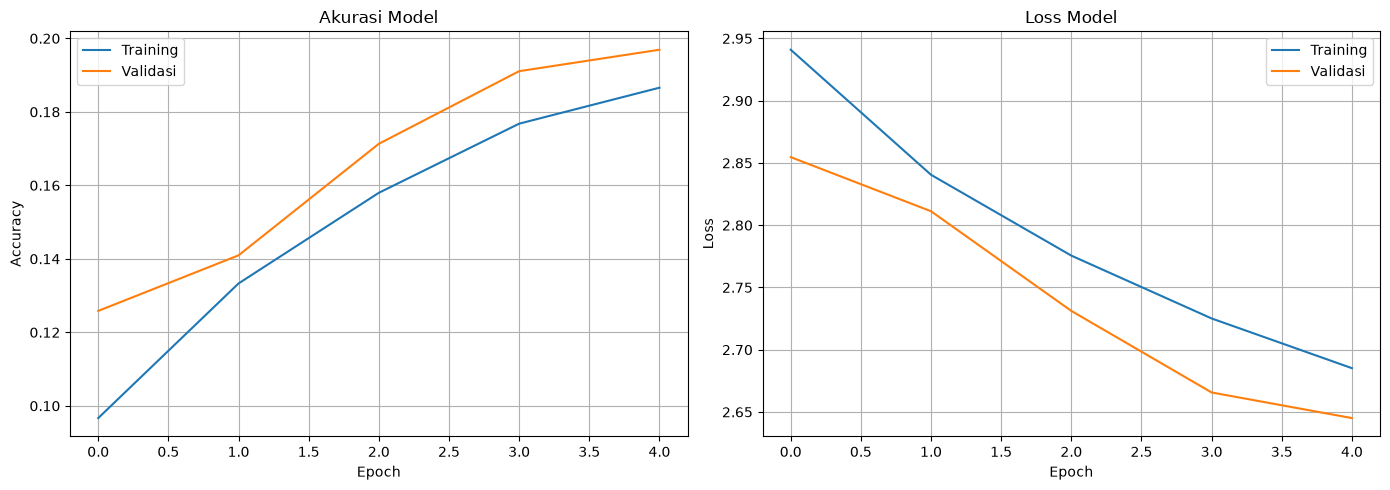

In [10]:

# ============================================================
# 10. VISUALISASI HASIL PELATIHAN
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Grafik akurasi
axes[0].plot(history.history["accuracy"], label="Training")
axes[0].plot(history.history["val_accuracy"], label="Validasi")
axes[0].set_title("Akurasi Model")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

# Grafik loss
axes[1].plot(history.history["loss"], label="Training")
axes[1].plot(history.history["val_loss"], label="Validasi")
axes[1].set_title("Loss Model")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


In [11]:

# ============================================================
# 11. EVALUASI MODEL
# ============================================================

# Menghitung probabilitas prediksi pada data validasi
y_prob = model.predict(val_dataset, verbose=1)

# Mengambil kelas dengan probabilitas tertinggi
y_pred = np.argmax(y_prob, axis=1)

# Menghitung metrik utama
accuracy = accuracy_score(y_val, y_pred)

print(f"Accuracy: {accuracy:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_val,
        y_pred,
        labels=np.arange(NUM_CLASSES),
        target_names=label_encoder.classes_,
        zero_division=0
    )
)


263/263 ━━━━━━━━━━━━━━━━━━━━ 7s 26ms/step
Accuracy: 0.1969

Classification Report:
                           precision    recall  f1-score   support

               All Beauty       0.13      0.05      0.07       400
          All Electronics       0.09      0.10      0.10       400
               Appliances       0.19      0.14      0.16       400
    Arts, Crafts & Sewing       0.00      0.00      0.00       400
               Automotive       0.49      0.10      0.16       400
                     Baby       0.18      0.37      0.24       400
            Baby Products       0.21      0.15      0.18       400
                   Beauty       0.18      0.44      0.25       400
Cell Phones & Accessories       0.19      0.57      0.28       400
Clothing, Shoes & Jewelry       0.21      0.37      0.27       400
              Electronics       0.19      0.44      0.27       400
   Grocery & Gourmet Food       0.26      0.42      0.32       400
   Health & Personal Care       0.24      0.1

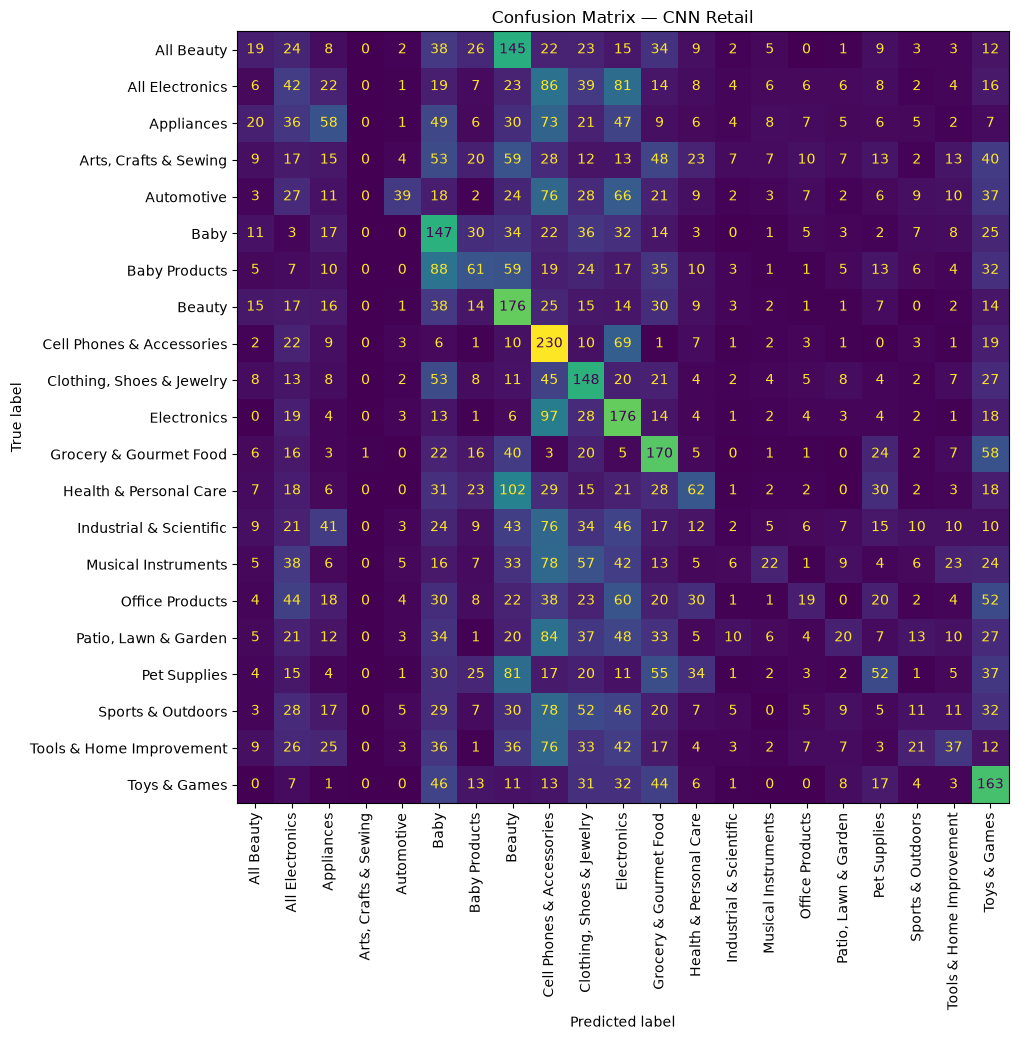

In [12]:

# ============================================================
# 12. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_val,
    y_pred,
    labels=np.arange(NUM_CLASSES)
)

# Untuk banyak kategori, visualisasi bisa menjadi sangat besar.
fig_size = min(max(10, NUM_CLASSES * 0.5), 24)

fig, ax = plt.subplots(figsize=(fig_size, fig_size))

display_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
)

display_cm.plot(
    ax=ax,
    xticks_rotation=90,
    colorbar=False,
    values_format="d"
)

plt.title("Confusion Matrix — CNN Retail")
plt.tight_layout()
plt.show()


In [13]:

# ============================================================
# 13. MENYIMPAN MODEL DAN HASIL EVALUASI
# ============================================================

# Membuat folder output jika belum ada
OUTPUT_DIR = BASE_DIR / "output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Menyimpan model yang telah dilatih
model.save(OUTPUT_DIR / "model_cnn_retail.keras")

# Menyimpan riwayat pelatihan
riwayat_df = pd.DataFrame(history.history)
riwayat_df.to_csv(
    OUTPUT_DIR / "riwayat_pelatihan.csv",
    index=False
)

# Menyimpan hasil prediksi validasi
hasil_validasi = pd.DataFrame({
    "label_aktual": label_encoder.inverse_transform(y_val),
    "label_prediksi": label_encoder.inverse_transform(y_pred)
})

hasil_validasi.to_csv(
    OUTPUT_DIR / "hasil_validasi.csv",
    index=False
)

print("Model dan hasil evaluasi berhasil disimpan di:", OUTPUT_DIR)


Model dan hasil evaluasi berhasil disimpan di: /Users/nikentriwardani/Desktop/ADVANCE/Tugas UTS_retail-cnn-classofocation/output



## Kesimpulan

Penelitian ini mengembangkan model Convolutional Neural Network untuk mengklasifikasikan gambar produk retail berdasarkan kategori pada dataset. Kinerja model dievaluasi menggunakan accuracy, precision, recall, F1-score, serta confusion matrix.

Nilai evaluasi aktual diperoleh setelah model selesai dilatih dan diuji pada data validasi. Hasil tersebut digunakan untuk menilai kemampuan model mengenali kategori produk serta mengidentifikasi kategori yang masih sering tertukar.

## Catatan Keterbatasan

1. Hasil model dipengaruhi kualitas gambar dan distribusi jumlah data pada setiap kategori.
2. Ukuran gambar dan jumlah epoch dipilih sebagai konfigurasi awal agar pelatihan lebih ringan.
3. Data validasi berasal dari pembagian dataset berlabel, bukan dari `test.csv`.
4. Nilai metrik harus dilaporkan berdasarkan output eksperimen aktual dan tidak boleh ditentukan sebelum pelatihan dilakukan.
